In [3]:
import csv
import json
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from scipy.optimize import brentq
from scipy.special import gammaln, kve

ELL = 1.0
RADII = ELL * np.geomspace(0.01, 4.0, 1600)
Y_LIMITS = (1e-3, 2e4)

FIG_DIR = Path("figs")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"Ready: {RADII.size} radii, R/ell in "
      f"[{RADII[0] / ELL:g}, {RADII[-1] / ELL:g}].")

Ready: 1600 radii, R/ell in [0.01, 4].


In [4]:
@dataclass(frozen=True)
class Profile:
    name: str
    label: str
    family: str
    ell: float = 1.0
    shape: float | None = None

    def log_matern_factor(self, s, order: float):
        """Log of the normalized Matérn factor of the given order."""
        s = np.asarray(s, dtype=float)
        if np.any(s < 0):
            raise ValueError("The squared-distance argument must be nonnegative.")

        b = (self.shape - 1.0) / self.ell**2
        t = b * s
        z = 2.0 * np.sqrt(t)
        positive = t > 0
        safe_t = np.where(positive, t, 1.0)
        safe_z = np.where(positive, z, 2.0)
        result = (
            np.log(2.0) + 0.5 * order * np.log(safe_t)
            - gammaln(order) + np.log(kve(order, safe_z)) - safe_z
        )
       
        return np.where(positive, np.minimum(result, 0.0), 0.0)

    def derivative(self, s, k: int = 0):
        """Analytic derivative h^(k)(s) for k = 0, 1, 2."""
        if k not in (0, 1, 2):
            raise ValueError("Only derivative orders 0, 1, and 2 are supported.")

        s = np.asarray(s, dtype=float)
        if np.any(s < 0):
            raise ValueError("The squared-distance argument must be nonnegative.")

        if self.family == "se":
            return (-1.0)**k * self.ell**(-2*k) * np.exp(-s / self.ell**2)

        if self.family == "rq":
            a = self.shape
            moment = np.exp(gammaln(a+k) - gammaln(a)) / (a*self.ell**2)**k
            return (-1.0)**k * moment * np.exp(
                -(a+k) * np.log1p(s / (a*self.ell**2))
            )

        if self.family == "matern":
            nu = self.shape
            if nu <= k:
                raise ValueError("The required Matérn derivative is not finite at zero.")
            b = (nu-1.0) / self.ell**2
            moment = b**k * np.exp(gammaln(nu-k) - gammaln(nu))
            return (-1.0)**k * moment * np.exp(self.log_matern_factor(s, nu-k))

        raise ValueError(f"Unknown profile family: {self.family}")

    def one_minus_h(self, s):
        """Evaluate 1 - h(s) with expm1 to limit cancellation near zero."""
        s = np.asarray(s, dtype=float)
        if self.family == "se":
            return -np.expm1(-s / self.ell**2)
        if self.family == "rq":
            a = self.shape
            return -np.expm1(-a * np.log1p(s / (a*self.ell**2)))
        return -np.expm1(self.log_matern_factor(s, self.shape))

    def gamma3(self):
        """Return -h'''(0+), or None when it is infinite."""
        if self.family == "se":
            return self.ell**(-6)
        if self.family == "rq":
            a = self.shape
            return (a+1)*(a+2) / (a*a*self.ell**6)

        nu = self.shape
        if nu <= 3:
            return None
        return (nu-1)**2 / ((nu-2)*(nu-3)*self.ell**6)


def default_profiles(ell=1.0):
    return [
        Profile("squared_exponential", "Squared exponential", "se", ell),
        Profile("rational_quadratic", r"Rational quadratic ($a=1$)", "rq", ell, 1.0),
        Profile("matern_5_2", r"Matérn ($\nu=5/2$)", "matern", ell, 2.5),
        Profile("matern_7_2", r"Matérn ($\nu=7/2$)", "matern", ell, 3.5),
        Profile("matern_9_2", r"Matérn ($\nu=9/2$)", "matern", ell, 4.5),
    ]


PROFILES = default_profiles(ELL)

for profile in PROFILES:
    np.testing.assert_allclose(profile.derivative(0.0), 1.0)
    np.testing.assert_allclose(profile.derivative(0.0, 1), -ELL**(-2))

print(f"Profiles ready: {len(PROFILES)}")

Profiles ready: 5


In [5]:
def envelope_components(profile: Profile, radius):
    """Return the three terms of V_h(R) and their sum."""
    radius = np.asarray(radius, dtype=float)
    if np.any(radius < 0):
        raise ValueError("R must be nonnegative.")

    h1 = float(profile.derivative(0.0, 1))
    h2 = float(profile.derivative(0.0, 2))
    t = 2.0 * radius**2

    a = 2.0 * profile.one_minus_h(8.0 * radius**2)
    b = 16.0 * radius**2 * np.maximum(
        -h1 + 2.0 * profile.derivative(t, 1), 0.0
    )
    c = 16.0 * radius**4 * np.maximum(
        h2 - 2.0 * profile.derivative(t, 2), 0.0
    )
    return a, b, c, a + b + c


def activation_radii(profile: Profile):
    """Find the radii where the B and C terms become active."""
    h1 = float(profile.derivative(0.0, 1))
    h2 = float(profile.derivative(0.0, 2))

    coefficients = (
        lambda r: -h1 + 2.0 * float(profile.derivative(2.0*r*r, 1)),
        lambda r: h2 - 2.0 * float(profile.derivative(2.0*r*r, 2)),
    )

    roots = []
    for coefficient in coefficients:
        upper = profile.ell
        while coefficient(upper) <= 0.0:
            upper *= 2.0
            if upper / profile.ell > 1e8:
                raise RuntimeError("Failed to bracket an activation radius.")
        roots.append(
            brentq(coefficient, 0.0, upper,
                   xtol=2e-14 * profile.ell, rtol=1e-13)
        )

    return tuple(roots)


ENVELOPES = {}
ACTIVATION_RADII = {}

print(f"{'Profile':<22} {'B: R/ell':>10} {'C: R/ell':>10}")
for profile in PROFILES:
    envelope = envelope_components(profile, RADII)[3]
    r_b, r_c = activation_radii(profile)

    ENVELOPES[profile.name] = envelope
    ACTIVATION_RADII[profile.name] = (r_b, r_c)

    print(f"{profile.name:<22} {r_b/profile.ell:10.6f} {r_c/profile.ell:10.6f}")

Profile                  B: R/ell   C: R/ell
squared_exponential      0.588705   0.588705
rational_quadratic       0.455090   0.360500
matern_5_2               0.484497   0.200094
matern_7_2               0.521061   0.375290
matern_9_2               0.538518   0.440377


In [9]:
REGIME_COLORS = ("#E8F2F9", "#FFF3D4", "#F0F0F0")


def make_envelope_figure(profiles, basename):
    """Plot one envelope per panel and save the figure as PDF and PNG."""
    style = {
        "font.family": "serif",
        "font.serif": ["DejaVu Serif"],
        "mathtext.fontset": "dejavuserif",
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 9,
        "axes.linewidth": 0.65,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
    }

    pdf_path = FIG_DIR / f"{basename}.pdf"
    png_path = FIG_DIR / f"{basename}.png"
    x = RADII / ELL

    with plt.rc_context(style):
        fig, axes = plt.subplots(
            1, len(profiles), figsize=(6.85, 3.0),
            sharex=True, sharey=True, squeeze=False
        )
        fig.subplots_adjust(
            left=0.105, right=0.985, bottom=0.20, top=0.76, wspace=0.13
        )

        for panel, (profile, ax) in enumerate(zip(profiles, axes[0])):
            low, high = sorted(
                r / profile.ell for r in ACTIVATION_RADII[profile.name]
            )
            zones = (
                (x[0], low, REGIME_COLORS[0]),
                (low, high, REGIME_COLORS[1]),
                (high, x[-1], REGIME_COLORS[2]),
            )
            for left, right, color in zones:
                left, right = max(left, x[0]), min(right, x[-1])
                if right - left > 1e-10:
                    ax.axvspan(left, right, facecolor=color,
                               edgecolor="none", zorder=0)

            ax.plot(x, ENVELOPES[profile.name], color="#181818",
                    linewidth=1.9, zorder=3)
            for root in sorted({round(low, 12), round(high, 12)}):
                ax.axvline(root, color="#777777", linestyle=(0, (2.5, 2.5)),
                           linewidth=0.7, zorder=2)

            ax.set_title(f"({chr(97 + panel)}) {profile.label}", pad=8)
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_xlim(x[0], x[-1])
            ax.set_ylim(*Y_LIMITS)
            ax.set_xticks([0.01, 0.1, 1.0, 4.0])
            ax.set_xticklabels([r"$10^{-2}$", r"$10^{-1}$", r"$1$", r"$4$"])
            ax.set_yticks([1e-3, 1e-1, 1e1, 1e3])
            ax.grid(True, which="major", color="#A5A5A5",
                    alpha=0.32, linewidth=0.45)
            ax.tick_params(which="major", direction="out", width=0.65, length=3.0)
            ax.tick_params(which="minor", direction="out", width=0.4, length=1.8)
            ax.label_outer()

        fig.text(0.545, 0.055, r"Normalized radius $R/\ell$",
                 ha="center", va="center", fontsize=10)
        fig.text(0.021, 0.485, r"Variance envelope $V_h(R)$", rotation=90,
                 ha="center", va="center", fontsize=10)

        regime_labels = ("Local envelope", "Transition", "Far envelope")
        handles = [
            Patch(facecolor=color, edgecolor="#BBBBBB", linewidth=0.4, label=label)
            for color, label in zip(REGIME_COLORS, regime_labels)
        ]
        fig.legend(
            handles=handles, loc="upper center", bbox_to_anchor=(0.545, 0.995),
            ncol=3, frameon=False, columnspacing=1.5, handlelength=1.6,
            handletextpad=0.55, borderaxespad=0.25
        )

        fig.savefig(
            pdf_path,
            metadata={
                "Title": "Pointwise variance envelope: "
                         + ", ".join(profile.name for profile in profiles),
                "Creator": "01_variance_envelopes.ipynb",
            },
        )
        fig.savefig(png_path, dpi=300)
        plt.show()
        plt.close(fig)

    return pdf_path, png_path

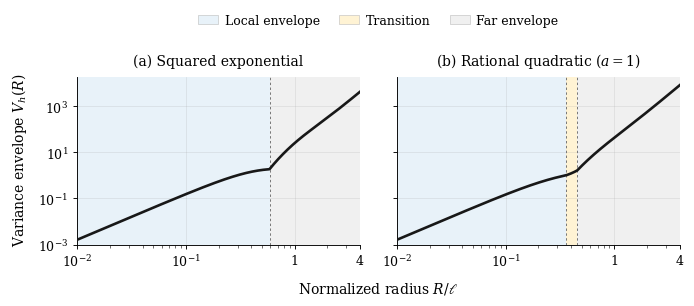

Saved: figs/variance_envelope_se_rq.pdf
Saved: figs/variance_envelope_se_rq.png


In [10]:
figure2_pdf, figure2_png = make_envelope_figure(
    PROFILES[:2], "variance_envelope_se_rq"
)

print(f"Saved: {figure2_pdf}")
print(f"Saved: {figure2_png}")

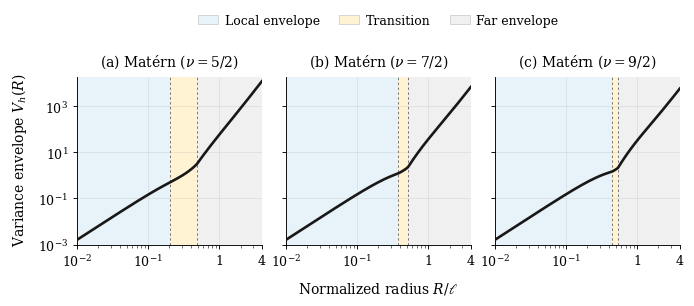

Saved: figs/variance_envelope_matern.pdf
Saved: figs/variance_envelope_matern.png


In [11]:
figure3_pdf, figure3_png = make_envelope_figure(
    PROFILES[2:], "variance_envelope_matern"
)

print(f"Saved: {figure3_pdf}")
print(f"Saved: {figure3_png}")